In [1]:
import os
import numpy as np
import scipy as sp
import pynwb
import pandas as pd
from matplotlib import pyplot as plt

prefix = '../data/mouse-2023-vickers/Fig4/'

In [2]:
filepath = prefix + 'Fig_4_nwbfile_2367_200309_E210_1_00001_00001_20220912-140732.nwb'
nwbfile = pynwb.read_nwb(filepath)

/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.5.1 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.4.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'hdmf-experimental' version 0.2.0 because version 0.5.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/pynwb/core.py:56: UserWarning: TimeSeries 'bsoid_timeseries': Length of data does not match length of 

In [3]:
neural_data = nwbfile.get_acquisition('dfof_timeseries')

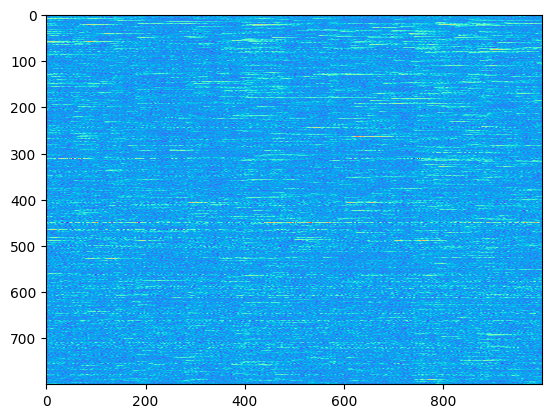

In [4]:
plt.imshow(neural_data.data[:800, :1000], aspect='auto', cmap='rainbow', interpolation='none')

In [5]:
import h5py

h5file = h5py.File(prefix + 'Fig_4_2367_200309_E210_1.mat', 'r')

def print_structure(name, obj):
	print(name)
	return name

h5file.visititems(print_structure)

FL_CAM


'FL_CAM'

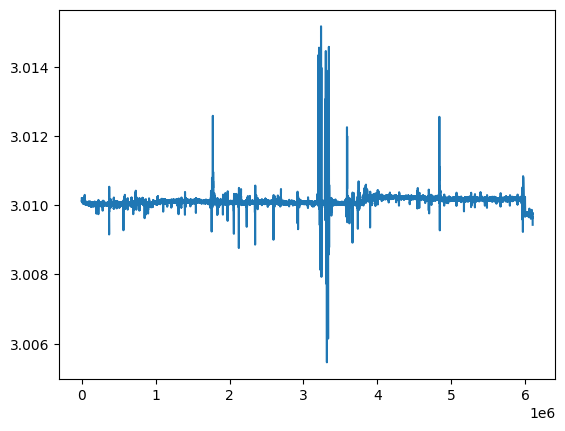

In [6]:
data_walk = h5file['Walk/values'][:]

plt.plot(data_walk[0, :])

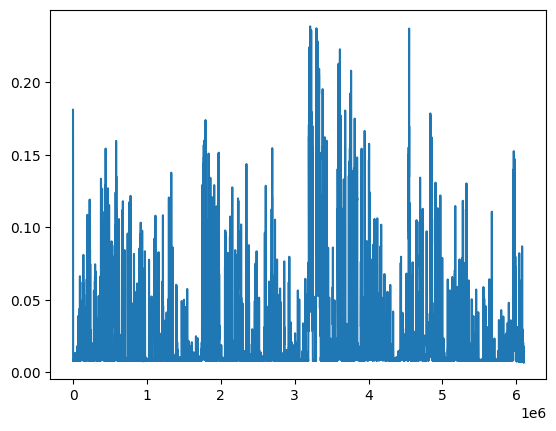

In [7]:
data_whisk = h5file['Rt_whsk/values'][:]
plt.plot(data_whisk[0, :])

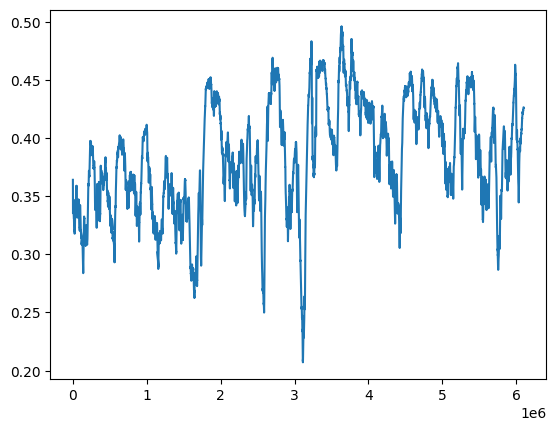

In [8]:
data_whisk = h5file['Rt_PPL/values'][:]
plt.plot(data_whisk[0, :])

In [12]:
keys = list()

def print_structure_ret(name, obj):
	if name.endswith('/values'):
		print(name)
		keys.append(name)

h5file.visititems(print_structure_ret)

Lft_PPL/values
Lft_ex/values
Lft_whsk/values
NI_PZO/values
P_diode/values
Piezo_co/values
Rt_PPL/values
Rt_ex/values
Rt_whsk/values
V2P_fr_cl/values
Walk/values
sound/values
test/values


In [15]:
datas = list()
for key in keys:
	datas.append(h5file[key])

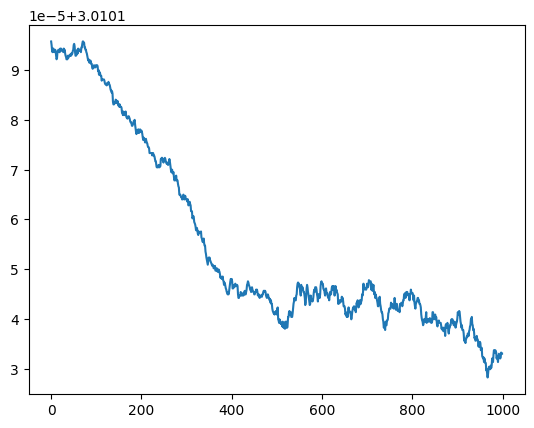

In [51]:
for data in datas[10:11]:
	plt.plot(data[0, :1000])